# 02 · Representation: decoding, specificity, separation (Results ¶5–¶6, Fig. 2, Fig. S1)

> **Provenance.** Built with the `repro-notebook` workflow (one executed notebook per experiment,
> every reported number checked against the produced one). Target paper: *Conversational Relevance in the
> Conjunction Fallacy Is Represented in Language Models* (`docs/paper/main_A.tex` in the authors' working
> repository; the released copy of the manuscript is the submission PDF). Companion documents:
> `REPRODUCTION_MANIFEST.md` (paper number → source CSV → producing script) and `REPRODUCTION_REPORT.md`
> (aggregated verdicts). Status legend: ✅ reproduced to the reported precision · ❌ does not match ·
> ⚠ presence check only · ⛔ cannot be recomputed from the released files.

## Source and code map

| id | what | data read here | original producing script |
|---|---|---|---|
| B1 | held-out AUC, gates | `results/rq3_pcr_locked_20260825/analysis/rq3a_context_decoder_robustness.csv`, `additional_Qs/rq3_run_server/analysis/rq3a_context_decoder_robustness.csv` | `analysis/rq3/analyze_rq3_context_decoding_robustness.py` ← `run_rq3_representation_gpu.py` |
| B2 | specificity gaps | `rq3a_specificity_gap_summary.csv` (both runs) | `analysis/rq3/analyze_rq3_h3a_specificity_gap.py` |
| B3 | R\|PC and PC\|R | `joint_r_pc_iut_no_holm/component_tests.csv` (both runs) | `analysis/rq3/analyze_rq3_joint_pcr_iut.py` |
| B4 | projection removal fractions | `additional_Qs/rpc_vector_control/cells.csv` | `additional_Qs/analysis/15_rpc_vector_control.py` |
| B5 | held-out ROC scores, depth profile | `docs/paper/figs/paper2/figS1_decoding_scores.csv`, `rq3a_layer_curves_h3_locked_20260825.csv` | `sim/make_paper_fig_pipeline.py` |
| E6 | deviation 8: split-half reliability | `rq3x_norming_quality_locked_20260825.csv` | `analysis/rq3/analyze_rq3_norming_quality.py` |

Everything is **loaded**; the only recomputation is the AUC from the cached held-out scores (B5), which checks the cache.

In [1]:
import sys, warnings
sys.path.insert(0, str(__import__('pathlib').Path.cwd() / 'notebooks'))
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from repro_utils import *
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 60,
              'display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
print('repository root:', ROOT.name)
C = Checks('02_representation')

repository root: release


## B1 · Relevance is decodable from held-out activations and is larger at the relevance conjunct

Reported: AUC **0.704** in **12/12** cells at 15 items and **0.803** at 165; at 15 items the gate passes
**1/12** for $h_2$ and **3/12** for $h_1$; at 165 the permutation gate saturates and passes all **48** cells,
down to AUC **0.516**.

In [2]:
def gate_table(path):
    r = six(read(path))
    r['gate'] = r.decode_gate.astype(str).str.lower().isin(['true', '1'])
    return r, r.groupby('family').agg(cells=('gate', 'size'), passed=('gate', 'sum'), mean_auc=('auc_nested_loio', 'mean'), min_auc=('auc_nested_loio', 'min'))
r15, g15 = gate_table(PCR / 'rq3a_context_decoder_robustness.csv'); r165, g165 = gate_table(S165 / 'rq3a_context_decoder_robustness.csv')
print('15 items'); display(g15); print('165 items'); display(g165)
C.num('B1', 'Results ¶5', 'held-out AUC h3, 15 items', '0.704', g15.loc['conjunction_h3', 'mean_auc'], rel(PCR / 'rq3a_context_decoder_robustness.csv'))
C.frac('B1', 'Results ¶5', 'h3 cells passing the gate, 15 items', '12/12', g15.loc['conjunction_h3', 'passed'], g15.loc['conjunction_h3', 'cells'])
C.frac('B1', 'Results ¶5', 'h2 control cells passing, 15 items', '1/12', g15.loc['conjunction_h2', 'passed'], g15.loc['conjunction_h2', 'cells'])
C.frac('B1', 'Results ¶5', 'h1 (base) control cells passing, 15 items', '3/12', g15.loc['base', 'passed'], g15.loc['base', 'cells'])
C.num('B1', 'Results ¶5', 'held-out AUC h3, 165 items', '0.803', g165.loc['conjunction_h3', 'mean_auc'], rel(S165 / 'rq3a_context_decoder_robustness.csv'))
C.frac('B1', 'Results ¶5', 'all cells pass at 165 items (gate saturates)', '48/48', g165.passed.sum(), g165.cells.sum())
C.num('B1', 'Results ¶5', 'lowest AUC that still passes at 165 items', '0.516', r165[r165.gate].auc_nested_loio.min())

15 items


,cells,passed,mean_auc,min_auc
family,,,,
base,12,3,0.5144,0.4844
conjunction,12,12,0.6347,0.5389
conjunction_h2,12,1,0.5100,0.4711
conjunction_h3,12,12,0.7037,0.5867


165 items


,cells,passed,mean_auc,min_auc
family,,,,
base,12,12,0.5904,0.5164
conjunction,12,12,0.6689,0.6135
conjunction_h2,12,12,0.5704,0.5256
conjunction_h3,12,12,0.8031,0.6069


## B2 · Specificity as an AUC gap (Fig. 2b)

Reported: gap over the $h_2$ control **+0.194 [+0.146, +0.252]** (15) and **+0.233 [+0.176, +0.283]** (165);
over $h_1$ **+0.189** (15) and **+0.213 [+0.168, +0.248]** (165). Model-level intervals.

In [3]:
gs15 = read(PCR / 'rq3a_specificity_gap_summary.csv').set_index('control'); gs165 = read(S165 / 'rq3a_specificity_gap_summary.csv').set_index('control')
display(pd.concat({'15': gs15, '165': gs165}, axis=1))
C.num('B2', 'Results ¶5', 'gap over h2, 15 items', '+0.194', gs15.loc['conjunction_h2', 'gap_mean'], rel(PCR / 'rq3a_specificity_gap_summary.csv'))
C.num('B2', 'Results ¶5', 'gap over h2, 15 items: CI low', '+0.146', gs15.loc['conjunction_h2', 'model_lo'])
C.num('B2', 'Results ¶5', 'gap over h2, 15 items: CI high', '+0.252', gs15.loc['conjunction_h2', 'model_hi'])
C.num('B2', 'Results ¶5', 'gap over h2, 165 items', '+0.233', gs165.loc['conjunction_h2', 'gap_mean'], rel(S165 / 'rq3a_specificity_gap_summary.csv'))
C.num('B2', 'Results ¶5', 'gap over h2, 165 items: CI low', '+0.176', gs165.loc['conjunction_h2', 'model_lo'])
C.num('B2', 'Results ¶5', 'gap over h2, 165 items: CI high', '+0.283', gs165.loc['conjunction_h2', 'model_hi'])
C.num('B2', 'Results ¶5', 'gap over h1, 15 items', '+0.189', gs15.loc['base', 'gap_mean'])
C.num('B2', 'Results ¶5 / app:large', 'gap over h1, 165 items', '+0.213', gs165.loc['base', 'gap_mean'])
C.num('B2', 'Appendix app:large', 'gap over h1, 165 items: CI low', '+0.168', gs165.loc['base', 'model_lo'])
C.num('B2', 'Appendix app:large', 'gap over h1, 165 items: CI high', '+0.248', gs165.loc['base', 'model_hi'])
C.presence('B2', 'Fig. 2b caption', 'no model-level gap interval includes zero', 'true', str(bool(gs15.model_excludes_zero.all() and gs165.model_excludes_zero.all())))

15                                                                                                                       165                                                       \
               n_cells n_models gap_mean cell_lo cell_hi cell_excludes_zero model_lo model_hi model_excludes_zero cells_ci_excludes_zero n_cells n_models gap_mean cell_lo cell_hi cell_excludes_zero   
control                                                                                                                                                                                                 
base                12        6   0.1893  0.1522  0.2278               True   0.1533   0.2400                True                     12      12        6   0.2127  0.1724  0.2417               True   
conjunction         12        6   0.0690  0.0386  0.0991               True   0.0406   0.1043                True                      7      12        6   0.1343  0.0960  0.1679               True   
conjunction_h2      12        6   0.1937  0.1530  0.2352               True   0.1463   0.2519                True                     11      12        6   0.2327  0.1896  0.2707               True   

                                                                             
               model_lo model_hi model_excludes_zero cells_ci_excludes_zero  
control                                                                      
base             0.1676   0.2475                True                     11  
conjunction      0.0866   0.1727                True                     12  
conjunction_h2   0.1756   0.2830                True                     12

## B3 · The relevance component survives removing the measured norms; the reverse holds less often (Fig. 2c)

Reported: $R\mid PC$ decodable in **12/12** cells in both banks; $PC\mid R$ in **6/12** at 15 items and
**10/12** at 165. Source: `component_tests.csv` (`component_pass`).

In [4]:
for bank, path in [('15', PCR), ('165', S165)]:
    ct = six(read(path / 'joint_r_pc_iut_no_holm/component_tests.csv'))
    g = ct.groupby('target').component_pass.agg(['sum', 'size'])
    display(g.rename(columns={'sum': 'decodable', 'size': 'cells'}).assign(bank=bank))
    C.frac('B3', 'Results ¶6', f'R|PC decodable, {bank} items', '12/12', g.loc['R', 'sum'], g.loc['R', 'size'], rel(path / 'joint_r_pc_iut_no_holm/component_tests.csv'))
    C.frac('B3', 'Results ¶6', f'PC|R decodable, {bank} items', '6/12' if bank == '15' else '10/12', g.loc['PC', 'sum'], g.loc['PC', 'size'])

,decodable,cells,bank
target,,,
PC,6,12,15
R,12,12,15


,decodable,cells,bank
target,,,
PC,10,12,165
R,12,12,165


## B4 · How much of $v_R$ the projection removes (Results ¶6, Discussion ¶3)

Reported: the projection removes **76 %** of the norm of $v_R$ at 165 items and **67 %** at 15; $v_R$ holds
**72 %** of the norm of $v_{PC}$ (165). Source: `rpc_vector_control/cells.csv`, `contrast == did`, vector mode.
The 15-item figure was last quoted over seven models in the working notes (0.661); here it is recomputed over the six.

In [5]:
vc = read(VEC / 'cells.csv')
vc = vc[(vc.contrast == 'did') & (vc['mode'] == 'vector')]
vc = vc[vc.model.isin([m.split('/')[-1] for m in SIX])]
r165 = vc[(vc.run == 165) & (vc.target == 'R')]; r15 = vc[(vc.run == 15) & (vc.target == 'R')]
pc165 = vc[(vc.run == 165) & (vc.target == 'PC')]
print(f'165 items: {len(r165)} cells · share of v_R in the P–C plane {r165.v_R_in_PC_plane.mean():.3f}')
print(f'15 items : {len(r15)} cells · share of v_R in the P–C plane {r15.v_R_in_PC_plane.mean():.3f}')
print(f'165 items: share of v_PC on v_R {pc165.v_PC_on_v_R.mean():.3f}')
C.num('B4', 'Results ¶6', 'norm of v_R removed by the P–C plane, 165 items', '76%', 100 * r165.v_R_in_PC_plane.mean(), rel(VEC / 'cells.csv'))
C.num('B4', 'Results ¶6', 'norm of v_R removed by the P–C plane, 15 items (six models)', '67%', 100 * r15.v_R_in_PC_plane.mean())
C.num('B4', 'Discussion ¶3', 'norm of v_PC held by v_R, 165 items', '72%', 100 * pc165.v_PC_on_v_R.mean())
C.num('B4', 'Appendix app:deviations 4', 'squared share (58 % of squared norm quoted in working notes)', '0.58', r165.v_R_in_PC_plane.mean() ** 2, note='working-note value; the paper quotes the norm share')

165 items: 12 cells · share of v_R in the P–C plane 0.762
15 items : 12 cells · share of v_R in the P–C plane 0.670
165 items: share of v_PC on v_R 0.721


## B5 · Held-out ROC scores and depth profile (Fig. S1)

The cached per-item held-out scores behind Fig. S1 are re-scored here and compared with the stored cell AUCs; the
layer curve is drawn from `rq3a_layer_curves_h3_locked_20260825.csv`. Fig. S1c states that relevance is not
decodable in the first fifth of the stack and becomes decodable from roughly mid depth.

max |recomputed − stored| AUC over 12 cells: 0.0


,auc,decodable
depth,,
"(-0.001, 0.1]",0.5155,0.2391
"(0.1, 0.2]",0.5871,0.9250
"(0.2, 0.3]",0.6706,0.9737
"(0.3, 0.4]",0.7013,0.9000
"(0.4, 0.5]",0.7192,1.0000
"(0.5, 0.6]",0.7365,1.0000
"(0.6, 0.7]",0.7199,1.0000
"(0.7, 0.8]",0.6740,1.0000
"(0.8, 0.9]",0.6558,1.0000


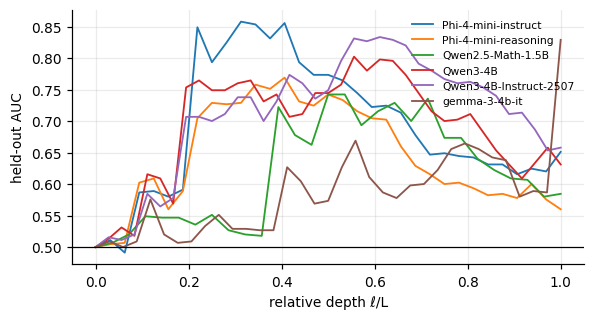

In [6]:
from sklearn.metrics import roc_auc_score
sc = read(FIGS / 'figS1_decoding_scores.csv')
re_auc = sc.groupby(['model', 'task']).apply(lambda g: roc_auc_score(g.label, g.score), include_groups=False)
stored = sc.groupby(['model', 'task']).auc_cell.first()
print('max |recomputed − stored| AUC over 12 cells:', float((re_auc - stored).abs().max()))
C.num('B5', 'Fig. S1a', 'mean AUC over the twelve cells from cached held-out scores', '0.704', re_auc.mean(), rel(FIGS / 'figS1_decoding_scores.csv'))
lc_ = six(read(PCR / 'rq3a_layer_curves_h3_locked_20260825.csv'))
lc_['depth'] = lc_.groupby('model_id').layer.transform(lambda s: s / s.max())
prof = lc_.groupby(pd.cut(lc_.depth, np.linspace(0, 1, 11), include_lowest=True), observed=True).agg(auc=('auc_loio', 'mean'), decodable=('decodable', 'mean'))
display(prof)
fig, ax = plt.subplots(figsize=(6, 3))
for m, g in lc_.groupby('model'):
    gg = g.groupby('depth').auc_loio.mean(); ax.plot(gg.index, gg.values, lw=1.2, label=m)
ax.axhline(.5, color='k', lw=.8); ax.set_xlabel('relative depth ℓ/L'); ax.set_ylabel('held-out AUC'); ax.legend(fontsize=7, frameon=False); plt.show()
first_fifth = lc_[lc_.depth <= .2].decodable.mean(); mid = lc_[(lc_.depth >= .45) & (lc_.depth <= .6)].decodable.mean()
C.presence('B5', 'Fig. S1c', 'not decodable in the first fifth, decodable from mid depth', 'qualitative', f'decodable share: first fifth {first_fifth:.2f}, mid depth {mid:.2f}')

## E6 · Deviation 8: Phi-4-mini-reasoning split-half reliability 0.409 (Δρ) and 0.193 (ΔC), below the 0.6 floor

In [7]:
nq = read(PCR / 'rq3x_norming_quality_locked_20260825.csv').set_index('model')
display(nq[['reliability_delta_P', 'reliability_delta_C', 'usable_P', 'usable_C']])
C.num('E6', 'Deviation 8', 'Phi-4-mini-reasoning split-half reliability of Δρ', '0.409', nq.loc['Phi-4-mini-reasoning', 'reliability_delta_P'], rel(PCR / 'rq3x_norming_quality_locked_20260825.csv'))
C.num('E6', 'Deviation 8', 'Phi-4-mini-reasoning split-half reliability of ΔC', '0.193', nq.loc['Phi-4-mini-reasoning', 'reliability_delta_C'])
C.presence('E6', 'Deviation 8', 'only Phi-4-mini-reasoning falls below the 0.6 floor', 'one model', ', '.join(nq.index[(nq.reliability_delta_P < .6) | (nq.reliability_delta_C < .6)]))

,reliability_delta_P,reliability_delta_C,usable_P,usable_C
model,,,,
Qwen2.5-Math-1.5B,0.9454,0.9898,True,True
Phi-4-mini-reasoning,0.4090,0.1931,False,False
DeepSeek-R1-Distill-Qwen-1.5B,0.8707,0.8150,True,True
gemma-3-4b-it,0.9858,0.9548,True,True
Qwen3-4B-Instruct-2507,0.9910,0.9899,True,True
Qwen3-4B,0.9871,0.9812,True,True
Phi-4-mini-instruct,0.9796,0.9876,True,True


## Figures 2 and S1

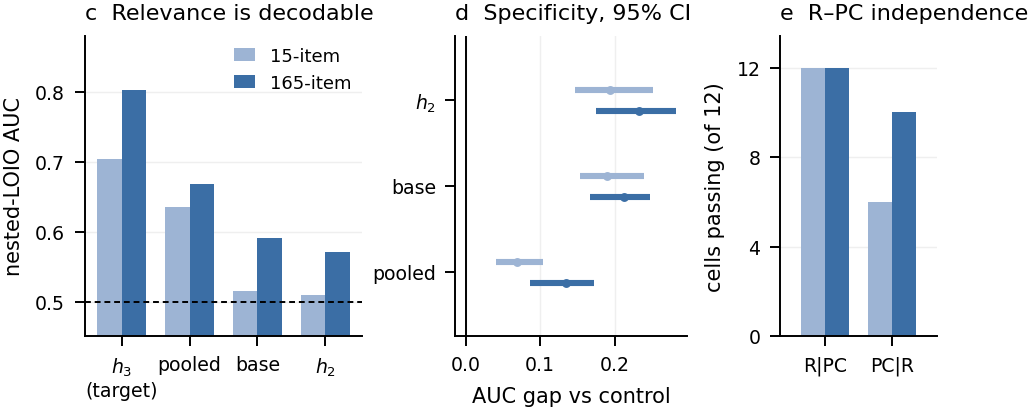

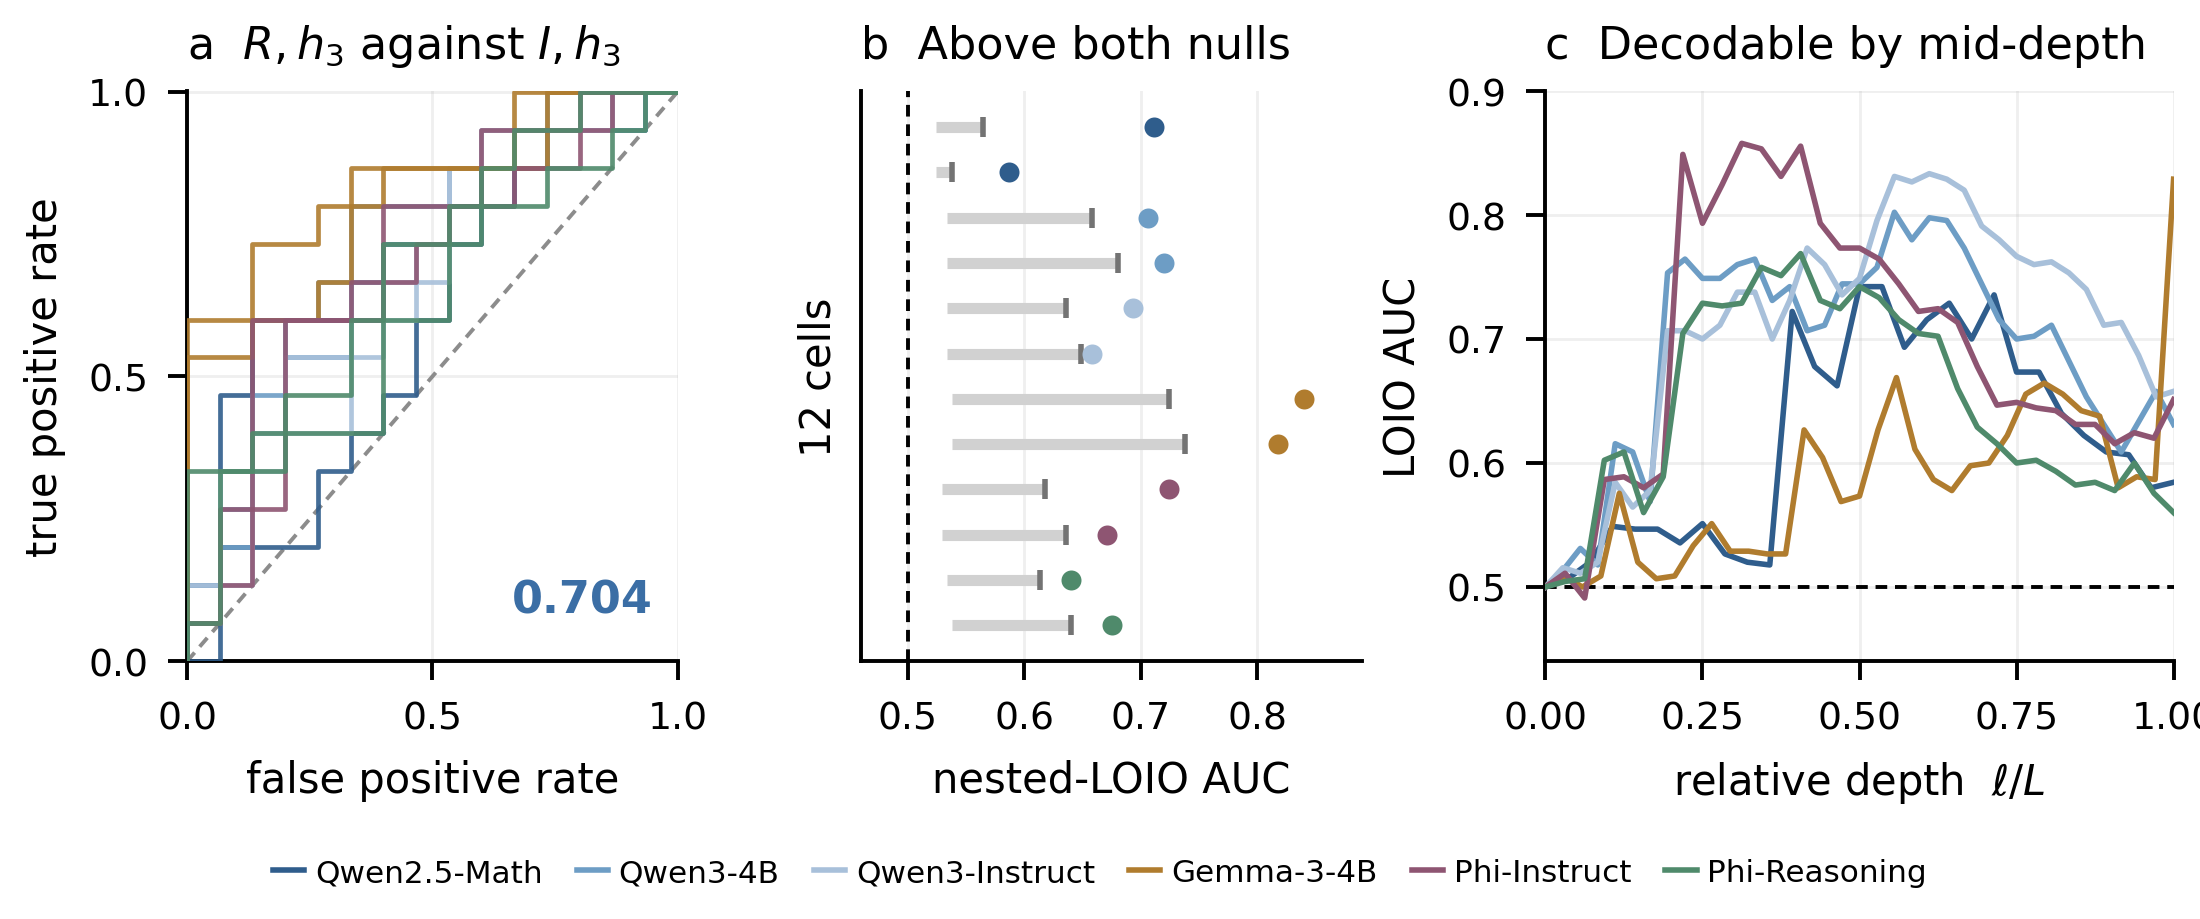

In [8]:
show_figure('fig2_representation.png', 820); show_figure('figS1_decoding.png', 900)

## Reproduction table for this notebook

In [9]:
df = C.show(); C.save('02')

02_representation: ✅ 28 · ⚠ 3


id,section,analysis,reported,produced,status,note
B1,Results ¶5,"held-out AUC h3, 15 items",0.704,+0.7037,✅,
B1,Results ¶5,"h3 cells passing the gate, 15 items",12/12,12/12,✅,
B1,Results ¶5,"h2 control cells passing, 15 items",1/12,1/12,✅,
B1,Results ¶5,"h1 (base) control cells passing, 15 items",3/12,3/12,✅,
B1,Results ¶5,"held-out AUC h3, 165 items",0.803,+0.8031,✅,
B1,Results ¶5,all cells pass at 165 items (gate saturates),48/48,48/48,✅,
B1,Results ¶5,lowest AUC that still passes at 165 items,0.516,+0.5164,✅,
B2,Results ¶5,"gap over h2, 15 items",+0.194,+0.1937,✅,
B2,Results ¶5,"gap over h2, 15 items: CI low",+0.146,+0.1463,✅,
B2,Results ¶5,"gap over h2, 15 items: CI high",+0.252,+0.2519,✅,


saved notebooks/_checks_02.csv
